# Exploratory statistical testing

This notebook tests the eleven numeric laboratory and demographic variables in `hcv_median_imputed.csv` (608 patients) for normality and for differences between the four diagnostic categories (Healthy, Hepatitis, Fibrosis, Cirrhosis). The workflow mirrors the reference analysis: normality tests and Q-Q plots, Kruskal-Wallis tests, then a quantile transformation followed by one-way ANOVA and a correlation heatmap. Every test table reports Bonferroni-adjusted p-values beside the raw p-values.

Outliers are deliberately not removed. In this dataset extreme laboratory values are part of the disease signal, so `cleaning.ipynb` only reports them.

## Configuration and data

Paths, the random seed, the significance level and the class order are fixed here so that every later cell uses the same values.

In [1]:
# Standard library, then third-party imports.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import QuantileTransformer

# Settings used throughout: file name, random seed, significance level,
# the target column and the fixed order of the four categories.
DATA_PATH = Path("hcv_median_imputed.csv")
SEED = 42
ALPHA = 0.05
TARGET = "Category"
CLASS_ORDER = ["Healthy", "Hepatitis", "Fibrosis", "Cirrhosis"]

# The 11 measurements we test. cat_num is a label code, so it is excluded.
NUMERIC_COLUMNS = [
    "Age", "ALB", "ALP", "ALT", "AST", "BIL",
    "CHE", "CHOL", "CREA", "GGT", "PROT",
]
PLOTS_PER_ROW = 4

In [2]:
# Read the cleaned data and fix the category order so that groups always
# appear as Healthy, Hepatitis, Fibrosis, Cirrhosis.
df = pd.read_csv(DATA_PATH)
df[TARGET] = pd.Categorical(df[TARGET], categories=CLASS_ORDER)

# Check the size and how many patients are in each category.
print(df.shape)
df[TARGET].value_counts()

(608, 14)


Category
Healthy      533
Cirrhosis     30
Hepatitis     24
Fibrosis      21
Name: count, dtype: int64

## Normality and data distribution analysis

For each variable we report the mean, median, standard deviation, skewness and excess kurtosis, together with the Shapiro-Wilk and D'Agostino-Pearson tests. Bonferroni adjustment treats the two tests across the eleven variables as one family of 22 comparisons, and a variable is labelled normal only if neither adjusted p-value falls below 0.05.

Median imputation creates repeated values, which can distort these tests, and the data are pooled across diagnoses. A non-significant result does not prove normality; it only means the test found no evidence against it.

In [3]:
# Collect one row of results per variable.
normality_rows = []
for column in NUMERIC_COLUMNS:
    values = df[column]

    # Shapiro-Wilk and D'Agostino-Pearson both test the null hypothesis
    # that the values come from a normal distribution.
    shapiro_w, shapiro_p = stats.shapiro(values)
    k2, k2_p = stats.normaltest(values)

    # Descriptive statistics help to explain why a test rejects normality.
    normality_rows.append({
        "Variable": column,
        "Mean": values.mean(),
        "Median": values.median(),
        "Std": values.std(),
        "Skewness": stats.skew(values),
        "Kurtosis": stats.kurtosis(values),
        "Shapiro W": shapiro_w,
        "Shapiro p": shapiro_p,
        "K2": k2,
        "K2 p": k2_p,
    })
normality_df = pd.DataFrame(normality_rows).set_index("Variable")

# Bonferroni: multiply each p-value by the number of tests in the family
# (11 variables x 2 tests = 22) and cap at 1, because a p-value cannot
# exceed 1. This guards against false positives from many tests.
family_size = len(NUMERIC_COLUMNS) * 2
normality_df["Shapiro p (adj)"] = (
    normality_df["Shapiro p"] * family_size).clip(upper=1)
normality_df["K2 p (adj)"] = (
    normality_df["K2 p"] * family_size).clip(upper=1)

# A variable counts as normal only if neither adjusted test rejects it.
normality_df["Normal"] = (
    (normality_df["Shapiro p (adj)"] >= ALPHA)
    & (normality_df["K2 p (adj)"] >= ALPHA)
)
normality_df.round(4)

,Mean,Median,Std,Skewness,Kurtosis,Shapiro W,Shapiro p,K2,K2 p,Shapiro p (adj),K2 p (adj),Normal
Variable,,,,,,,,,,,,
Age,47.2911,47.00,9.9927,0.2537,-0.4230,0.9840,0.0000,13.2406,0.0013,0.0001,0.0293,False
ALB,41.8191,42.00,5.4023,0.2924,6.1727,0.9429,0.0000,95.6194,0.0000,0.0000,0.0000,False
ALP,67.7671,66.00,24.8988,4.9428,63.1099,0.7658,0.0000,682.6496,0.0000,0.0000,0.0000,False
ALT,27.5938,23.00,21.2109,4.1690,30.1048,0.6812,0.0000,578.0350,0.0000,0.0000,0.0000,False
AST,34.3694,25.85,32.6224,5.1233,32.8477,0.4586,0.0000,654.1583,0.0000,0.0000,0.0000,False
BIL,11.4740,7.30,19.7706,8.3260,81.6672,0.3123,0.0000,901.0631,0.0000,0.0000,0.0000,False
CHE,8.2049,8.27,2.1684,-0.1550,1.3786,0.9795,0.0000,22.8756,0.0000,0.0000,0.0002,False
CHOL,5.3775,5.30,1.1102,0.4020,0.7714,0.9882,0.0001,24.9802,0.0000,0.0018,0.0001,False
CREA,81.5132,77.00,49.7207,15.3258,281.5685,0.2345,0.0000,1251.1555,0.0000,0.0000,0.0000,False


### Findings

Normality is rejected for all 11 variables: at least one Bonferroni-adjusted p-value is below 0.05 in every case, and the `Normal` column is `False` throughout. Age is the closest to normal (skewness 0.25, excess kurtosis -0.42), and it is rejected only narrowly by the D'Agostino-Pearson test (adjusted p 0.0293) and clearly by Shapiro-Wilk (adjusted p 0.0001). CREA is the most extreme (skewness 15.33, excess kurtosis 281.57), followed by BIL (skewness 8.33, kurtosis 81.67) and ALP (skewness 4.94, kurtosis 63.11). For AST, BIL, CREA and GGT the mean is well above the median (for example BIL 11.47 against 7.30), which reflects a long right tail.

## Q-Q plots

A Q-Q plot compares sample quantiles with those of a normal distribution; points on the line indicate normality, and systematic curvature shows skewness or heavy tails. This complements the tests above by showing the shape of any departure.

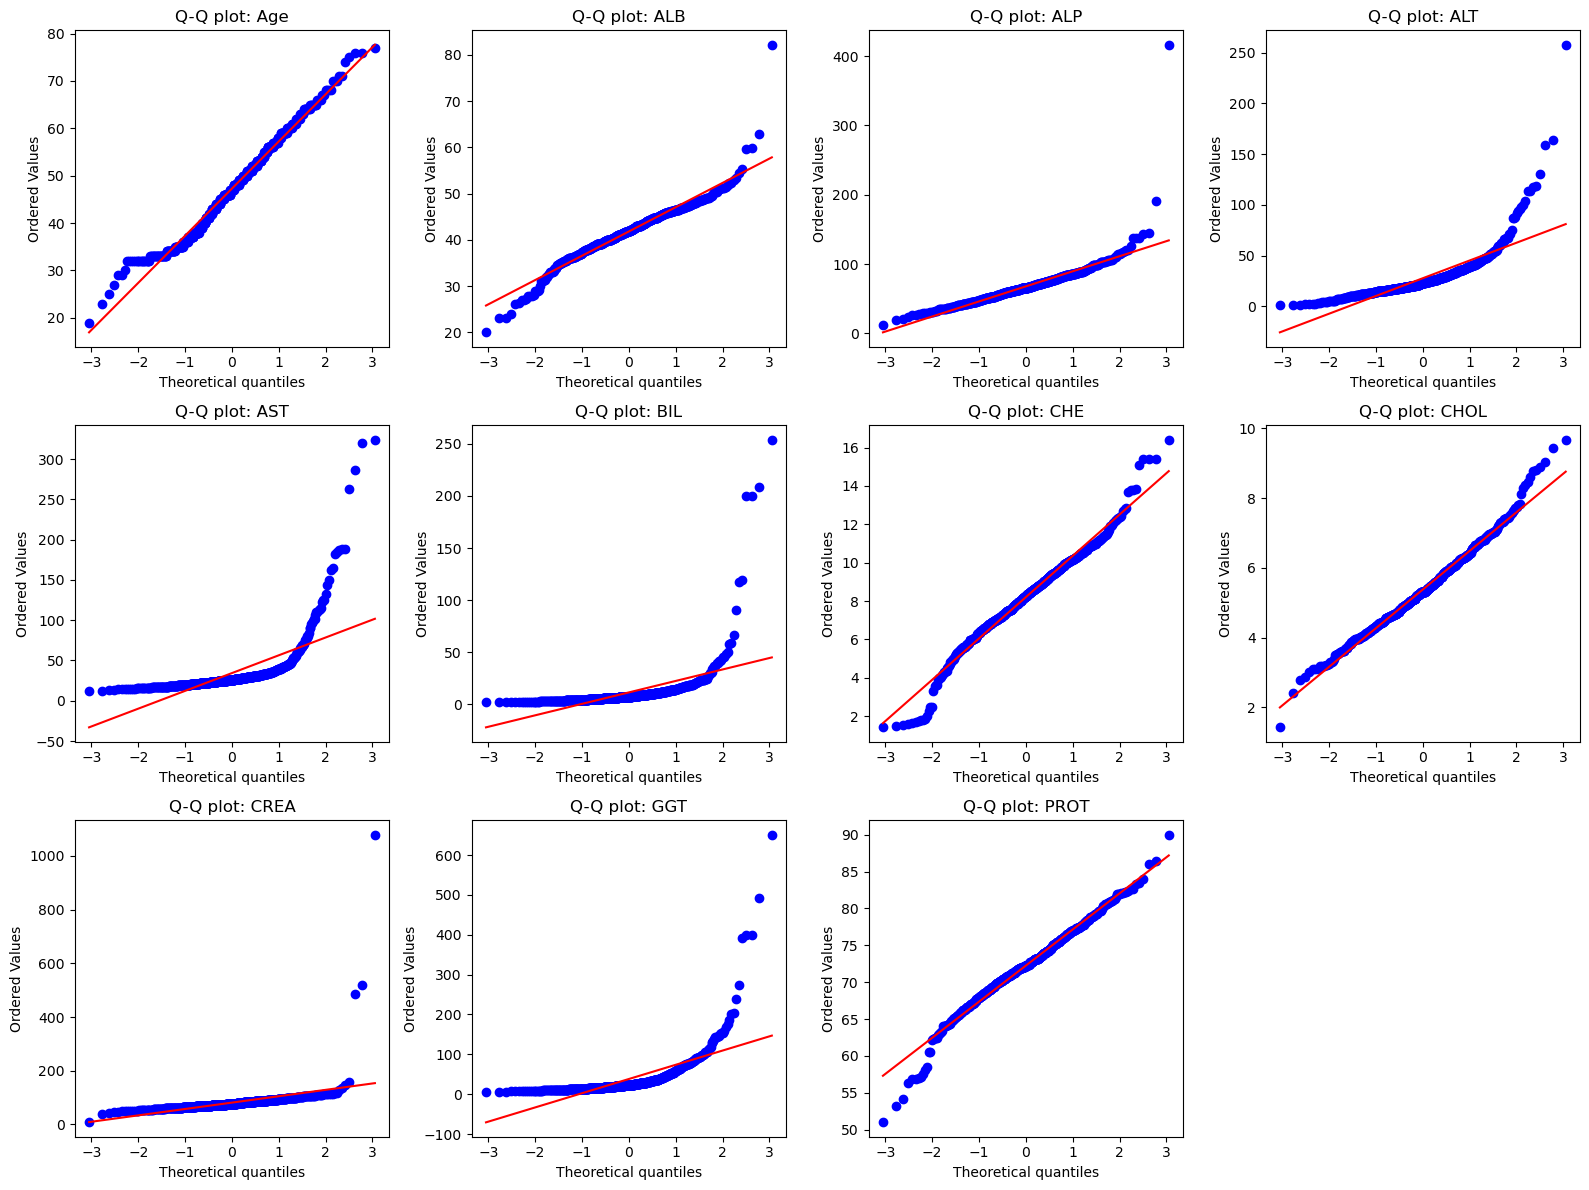

In [4]:
# Lay the plots out in a grid with four per row.
n_rows = int(np.ceil(len(NUMERIC_COLUMNS) / PLOTS_PER_ROW))
fig, axes = plt.subplots(
    n_rows, PLOTS_PER_ROW, figsize=(4 * PLOTS_PER_ROW, 4 * n_rows))
axes = axes.flatten()

# A Q-Q plot compares the data with a normal distribution; points close
# to the line mean the data look normal.
for ax, column in zip(axes, NUMERIC_COLUMNS):
    stats.probplot(df[column], dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot: {column}")

# Remove the empty panels left in the last row.
for ax in axes[len(NUMERIC_COLUMNS):]:
    fig.delaxes(ax)
fig.tight_layout()
plt.show()

### Findings

The plots should be read against the table above. Variables with large skewness and kurtosis values (ALP, ALT, AST, BIL, CREA, GGT) are the ones expected to bend away from the reference line in the upper tail, consistent with the right-skewed distributions already reported. Age, CHE, CHOL and PROT, whose skewness lies between -0.40 and 0.40, are the closest to the line, although the tests still reject normality for them.

## Statistical testing

Because most variables depart from normality, group differences are first tested with the rank-based Kruskal-Wallis test, which makes no distributional assumption. Effect size is eta-squared based on H, eta2_H = (H - k + 1) / (n - k), labelled small (below 0.06), medium (below 0.14) or large (0.14 and above). Bonferroni adjustment uses a family of 11 tests, one per variable.

In [5]:
# Number of patients, number of groups and the order of the groups.
n = len(df)
k = len(CLASS_ORDER)

kruskal_rows = []
for column in NUMERIC_COLUMNS:
    # Split the variable into one set of values per category.
    groups = [df.loc[df[TARGET] == name, column] for name in CLASS_ORDER]

    # Kruskal-Wallis compares the ranks of the values across groups, so it
    # does not need the data to be normal.
    h_stat, p_value = stats.kruskal(*groups)

    # Effect size eta-squared based on H: how much of the variation is
    # explained by the category.
    eta_squared = (h_stat - k + 1) / (n - k)

    # Conventional labels for the size of the effect.
    if eta_squared < 0.06:
        magnitude = "small"
    elif eta_squared < 0.14:
        magnitude = "medium"
    else:
        magnitude = "large"

    kruskal_rows.append({
        "Variable": column,
        "H": h_stat,
        "p": p_value,
        "eta2_H": eta_squared,
        "Magnitude": magnitude,
    })
kruskal_df = pd.DataFrame(kruskal_rows)

# Bonferroni: multiply by the 11 tests and cap at 1.
kruskal_df["p (adj)"] = (
    kruskal_df["p"] * len(NUMERIC_COLUMNS)).clip(upper=1)
kruskal_df["Significant"] = kruskal_df["p (adj)"] < ALPHA

# Show the strongest effects first.
kruskal_df = kruskal_df.sort_values("eta2_H", ascending=False)
kruskal_df.set_index("Variable")

,H,p,eta2_H,Magnitude,p (adj),Significant
Variable,,,,,,
AST,158.142287,4.613425e-34,0.256858,large,5.074768e-33,True
GGT,106.328307,6.766970e-23,0.171073,large,7.443667e-22,True
BIL,93.648308,3.603991e-20,0.150080,large,3.964390e-19,True
CHE,67.088464,1.792767e-14,0.106107,medium,1.972043e-13,True
ALB,58.075653,1.514479e-12,0.091185,medium,1.665927e-11,True
CHOL,53.156349,1.697909e-11,0.083040,medium,1.867699e-10,True
ALP,46.093848,5.416796e-10,0.071347,medium,5.958476e-09,True
Age,29.465045,1.788107e-06,0.043816,small,1.966918e-05,True
ALT,21.859771,6.976358e-05,0.031225,small,7.673993e-04,True


### Findings

After Bonferroni adjustment (family of 11), 10 of the 11 variables differ significantly across the four categories. CREA is the exception (raw p 0.0166, adjusted p 0.1828, eta2_H 0.012). The largest effects are AST (H 158.14, eta2_H 0.257, large), GGT (eta2_H 0.171, large) and BIL (eta2_H 0.150, large). CHE (0.106), ALB (0.091), CHOL (0.083) and ALP (0.071) are medium, while Age (0.044), ALT (0.031), PROT (0.024) and CREA (0.012) are small. Significance alone is therefore not informative here; the effect sizes show that AST, GGT and BIL separate the categories most strongly. This test does not say which categories differ, and the groups are very unbalanced (Healthy 533 against 21 to 30 in each disease category).

## One-way ANOVA after quantile transformation

A quantile transformation maps each variable to a standard normal shape so that a parametric one-way ANOVA can be applied as a second view of the same question. The transformer is fitted on all of the data purely for exploratory testing, not for modelling; fitting it before a train-test split would leak information, so it is not reused as a modelling step here. Eta-squared is SS_between / SS_total, and the Bonferroni family is again 11 tests.

In [6]:
# Transform every variable so that it follows a normal distribution.
# n_quantiles is capped at the sample size to avoid a sklearn warning.
# The transformer is fitted on all the data; this is for exploration only.
transformer = QuantileTransformer(
    n_quantiles=len(df), output_distribution="normal",
    random_state=SEED)
df_transformed = df.copy()
df_transformed[NUMERIC_COLUMNS] = transformer.fit_transform(
    df[NUMERIC_COLUMNS])

anova_rows = []
for column in NUMERIC_COLUMNS:
    # One set of transformed values per category.
    groups = [
        df_transformed.loc[df_transformed[TARGET] == name, column]
        for name in CLASS_ORDER
    ]

    # One-way ANOVA tests whether the group means differ.
    f_stat, p_value = stats.f_oneway(*groups)

    # Effect size eta-squared: variation between group means divided by
    # the total variation (SS_between / SS_total).
    grand_mean = df_transformed[column].mean()
    ss_between = 0
    for group in groups:
        ss_between += len(group) * (group.mean() - grand_mean) ** 2
    ss_total = ((df_transformed[column] - grand_mean) ** 2).sum()

    anova_rows.append({
        "Variable": column,
        "F": f_stat,
        "p": p_value,
        "eta2": ss_between / ss_total,
    })
anova_df = pd.DataFrame(anova_rows)

# Bonferroni: multiply by the 11 tests and cap at 1.
anova_df["p (adj)"] = anova_df["p"] * len(NUMERIC_COLUMNS)
anova_df["p (adj)"] = anova_df["p (adj)"].clip(upper=1)
anova_df["Significant"] = anova_df["p (adj)"] < ALPHA

# Show the smallest p-values first.
anova_df = anova_df.sort_values("p")
anova_df.set_index("Variable")

,F,p,eta2,p (adj),Significant
Variable,,,,,
AST,85.597383,3.680313e-46,0.298321,4.048344e-45,True
GGT,48.926355,2.570264e-28,0.195502,2.827290e-27,True
BIL,46.470542,4.948759e-27,0.187530,5.443635e-26,True
CHE,42.320376,7.822367e-25,0.173691,8.604604e-24,True
ALB,30.599431,1.999838e-18,0.131932,2.199822e-17,True
CHOL,23.417681,2.380066e-14,0.104194,2.618073e-13,True
ALP,21.611954,2.626788e-13,0.096938,2.889466e-12,True
ALT,15.390551,1.165335e-09,0.071015,1.281868e-08,True
Age,14.778126,2.690075e-09,0.068382,2.959083e-08,True


### Findings

The ANOVA on transformed values agrees with the Kruskal-Wallis ranking. The same 10 variables are significant after adjustment, and CREA is not (F 2.18, raw p 0.0898, adjusted p 0.9882, eta2 0.011). AST again has the strongest effect (F 85.60, eta2 0.298), followed by GGT (0.196), BIL (0.188) and CHE (0.174). PROT is the weakest of the significant variables (eta2 0.039, adjusted p 0.0003). Because the conclusions match across a rank-based and a parametric test, the group differences are unlikely to be an artefact of non-normality. The ANOVA assumes equal variances and is sensitive to the unbalanced group sizes, and it was not checked for homogeneity of variance here.

## Correlation after transformation

The Pearson correlation matrix of the transformed variables, with the numeric category code `cat_num` included as in the reference, shows how the measurements relate to each other and to disease severity. Only the lower triangle is drawn because the matrix is symmetric.

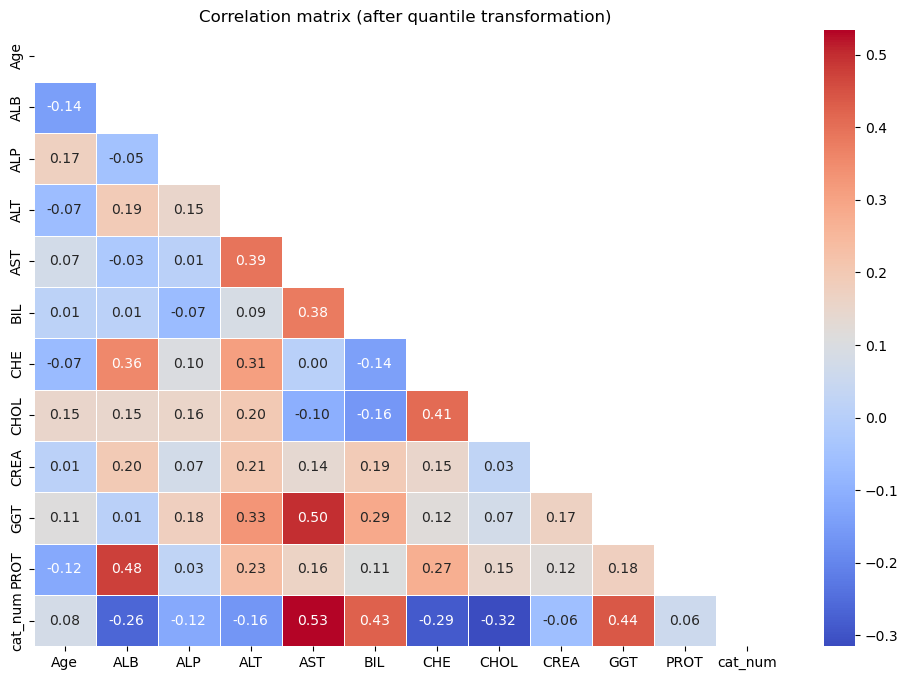

In [7]:
# Pearson correlation of the transformed variables, plus the category code.
corr_matrix = df_transformed[NUMERIC_COLUMNS + ["cat_num"]].corr(
    method="pearson")

# Hide the upper triangle, because the matrix is symmetric.
upper_triangle = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Draw the heatmap with the value printed to 2 decimal places.
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix, mask=upper_triangle, annot=True, fmt=".2f",
    cmap="coolwarm", linewidths=0.5,
)
plt.title("Correlation matrix (after quantile transformation)")
plt.show()

### Findings

`cat_num` correlates most strongly with AST (0.53), GGT (0.44) and BIL (0.43) in the positive direction, and with CHOL (-0.32), CHE (-0.29) and ALB (-0.26) in the negative direction. Age (0.08), PROT (0.06) and CREA (-0.06) are close to zero, matching their small or non-significant effects above. Among the measurements themselves the strongest pairs are AST and GGT (0.50), ALB and PROT (0.48), CHE and CHOL (0.41) and ALT and AST (0.39). These are correlations on transformed values and do not imply a causal link.

## Summary

None of the 11 variables is normally distributed (all adjusted p-values reject normality), mainly because of strong right skew and heavy tails, and outliers were kept as disease signal. Kruskal-Wallis tests found 10 of 11 variables to differ across Healthy, Hepatitis, Fibrosis and Cirrhosis after Bonferroni adjustment, with large effects for AST (eta2_H 0.257), GGT (0.171) and BIL (0.150). One-way ANOVA on quantile-transformed data gave the same set of significant variables, with AST again strongest (eta2 0.298). CREA was the only variable without a significant difference (adjusted p 0.1828 by Kruskal-Wallis, 0.9882 by ANOVA). In the transformed correlation matrix, `cat_num` is most associated with AST (0.53), GGT (0.44) and BIL (0.43). These tests are exploratory, describe group differences rather than predictive performance, and the unbalanced classes limit how far they can be generalised.